# Part-1: Time Series Fundamentals

**Time Series in Machine Learning** — Daneshkar.net

---


In [ ]:
# Install required packages 
# %pip install numpy
# %pip install pandas
# %pip install matplotlib
# %pip install statsmodels
# %pip install scipy
# %pip install scikit-learn

# Or install all at once:
#pip install numpy pandas matplotlib statsmodels scipy scikit-learn


In [ ]:
# Common imports & Jupyter setup
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Setup complete! Ready to run.")


Setup complete! Ready to run.


---
## Introduction To Time Series


In [ ]:

# Ensure output directory exists
OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)


## Section 1: Required Libraries


In [ ]:
print("Key libraries for time series analysis in Python:")
print("  pandas      - working with time-indexed data")
print("  numpy       - numerical computations")
print("  matplotlib  - plotting")
print("  statsmodels - statistical models (ARIMA, SARIMA)")
print("  scipy       - statistical tests")
print("  seaborn     - statistical visualizations")
print()


Key libraries for time series analysis in Python:
  pandas      - working with time-indexed data
  numpy       - numerical computations
  matplotlib  - plotting
  statsmodels - statistical models (ARIMA, SARIMA)
  scipy       - statistical tests
  seaborn     - statistical visualizations



## Section 2: Creating a Synthetic Time Series


Creating a synthetic time series: Trend + Seasonality + Noise...


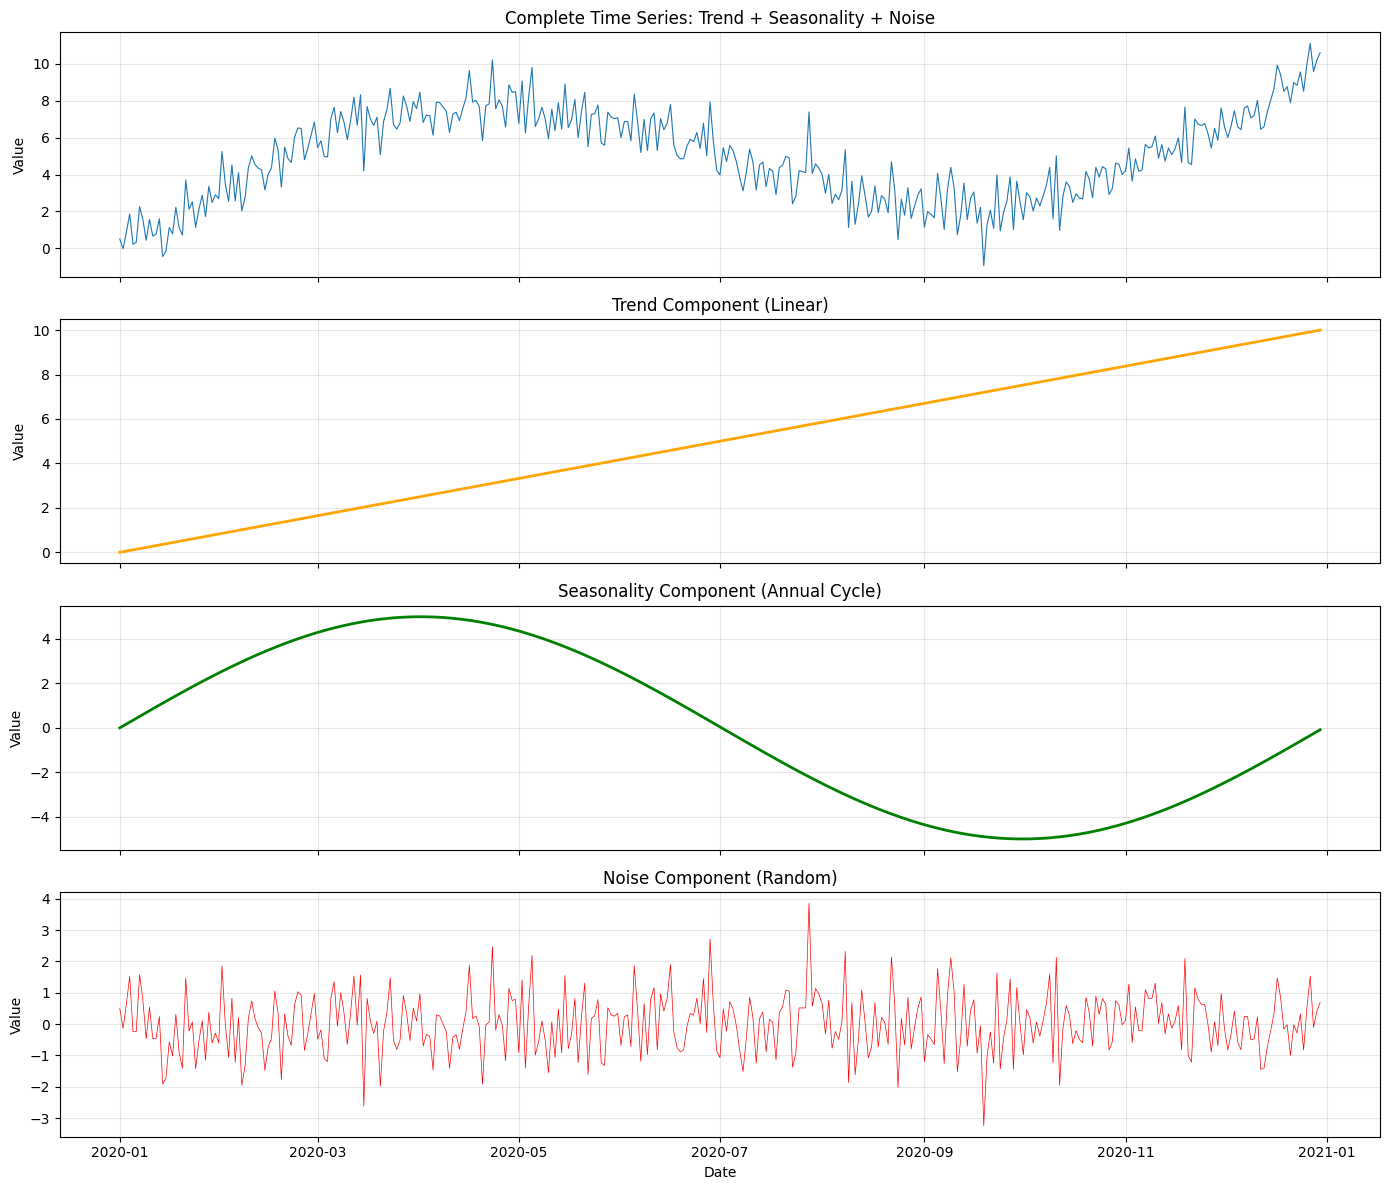

In [ ]:
print("Creating a synthetic time series: Trend + Seasonality + Noise...")

np.random.seed(42)
dates = pd.date_range(start='2020-01-01', periods=365, freq='D')
trend = np.linspace(0, 10, 365)                               # Linear trend
seasonality = 5 * np.sin(2 * np.pi * np.arange(365) / 365)    # Annual seasonal pattern
noise = np.random.normal(0, 1, 365)                           # Random noise

time_series = trend + seasonality + noise

# Plot components
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(dates, time_series, linewidth=0.8)
axes[0].set_title('Complete Time Series: Trend + Seasonality + Noise')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

axes[1].plot(dates, trend, color='orange', linewidth=2)
axes[1].set_title('Trend Component (Linear)')
axes[1].set_ylabel('Value')
axes[1].grid(True, alpha=0.3)

axes[2].plot(dates, seasonality, color='green', linewidth=2)
axes[2].set_title('Seasonality Component (Annual Cycle)')
axes[2].set_ylabel('Value')
axes[2].grid(True, alpha=0.3)

axes[3].plot(dates, noise, color='red', linewidth=0.5)
axes[3].set_title('Noise Component (Random)')
axes[3].set_ylabel('Value')
axes[3].set_xlabel('Date')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '01_time_series_components.png'), dpi=100)


## Section 3: Time Series Structure


In [ ]:
print()
print("Time Series = Trend + Seasonality + Cycle + Noise")
print(f"  Generated: {len(time_series)} daily observations")
print(f"  Date range: {dates[0].date()} to {dates[-1].date()}")
print(f"  Mean: {time_series.mean():.2f}, Std: {time_series.std():.2f}")

print("\nDone! Introduction to Time Series complete.")



Time Series = Trend + Seasonality + Cycle + Noise
  Generated: 365 daily observations
  Date range: 2020-01-01 to 2020-12-30
  Mean: 5.01, Std: 2.42

Done! Introduction to Time Series complete.


---
## TimeSeries vs Tabular Data


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
import os

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)


## Section 1: Why Shuffling Destroys Time Series


In [ ]:
print("=" * 60)
print("Section 1: Why Order Matters in Time Series")
print("=" * 60)

# Create a simple time series with a clear trend
dates = pd.date_range('2023-01-01', periods=20, freq='D')
df = pd.DataFrame({
    'value': np.arange(20) + np.random.normal(0, 0.5, 20)
}, index=dates)

print("\nOriginal ordered data:")
print(df.head(6).to_string())
print(f"\nAutocorrelation (lag=1) of original: {df['value'].autocorr(lag=1):.4f}")

# Shuffle and observe autocorrelation destruction
df_shuffled = df.sample(frac=1, random_state=42)
print(f"\nShuffled data (order destroyed):")
print(df_shuffled.head(6).to_string())
print(f"Autocorrelation (lag=1) of shuffled: {df_shuffled['value'].autocorr(lag=1):.4f}")
print(">>> See how shuffling destroyed the temporal structure!")


Section 1: Why Order Matters in Time Series

Original ordered data:
               value
2023-01-01 -0.200610
2023-01-02  1.112046
2023-01-03  2.006296
2023-01-04  3.048838
2023-01-05  3.613495
2023-01-06  5.012255

Autocorrelation (lag=1) of original: 0.9922

Shuffled data (order destroyed):
                value
2023-01-01  -0.200610
2023-01-18  15.938052
2023-01-16  14.580139
2023-01-02   1.112046
2023-01-09   8.479635
2023-01-06   5.012255
Autocorrelation (lag=1) of shuffled: -0.3036
>>> See how shuffling destroyed the temporal structure!


## Section 2: Autocorrelation Demo



Section 2: Autocorrelation (ACF)
Lag-1 autocorrelation: 0.7625
Lag-2 autocorrelation: 0.5901
Lag-7 autocorrelation: 0.2250


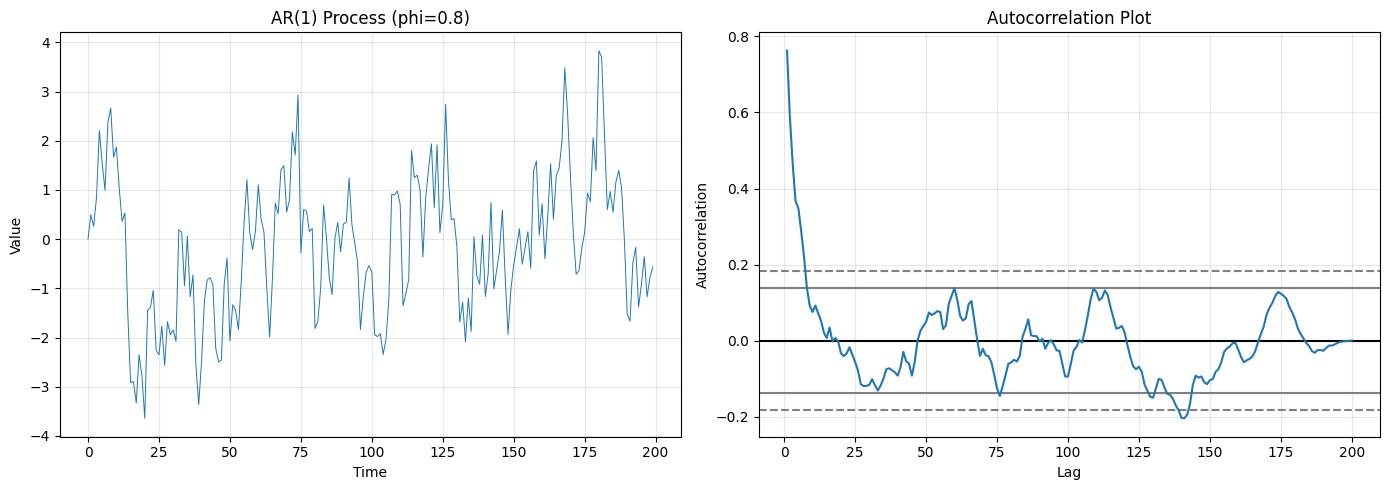

In [ ]:
print("\n" + "=" * 60)
print("Section 2: Autocorrelation (ACF)")
print("=" * 60)

# Generate AR(1) process: y_t = 0.8 * y_{t-1} + noise
np.random.seed(42)
n = 200
y = np.zeros(n)
for t in range(1, n):
    y[t] = 0.8 * y[t-1] + np.random.normal(0, 1)
y_series = pd.Series(y)

print(f"Lag-1 autocorrelation: {y_series.autocorr(lag=1):.4f}")
print(f"Lag-2 autocorrelation: {y_series.autocorr(lag=2):.4f}")
print(f"Lag-7 autocorrelation: {y_series.autocorr(lag=7):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(y_series.values, linewidth=0.7)
axes[0].set_title('AR(1) Process (phi=0.8)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

# Manual ACF for first 20 lags
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(y_series, ax=axes[1])
axes[1].set_title('Autocorrelation Plot')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('Autocorrelation')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_autocorrelation.png'), dpi=100)


## Section 3: Validation - TimeSeriesSplit vs K-Fold


In [ ]:
print("\n" + "=" * 60)
print("Section 3: TimeSeriesSplit vs Random K-Fold")
print("=" * 60)

X = np.arange(100).reshape(-1, 1)
y = np.arange(100)

print("\nTimeSeriesSplit (5 splits):")
tscv = TimeSeriesSplit(n_splits=5)
for i, (train_idx, test_idx) in enumerate(tscv.split(X)):
    print(f"  Split {i+1}: train=[{train_idx[0]}...{train_idx[-1]}] ({len(train_idx)} samples), "
          f"test=[{test_idx[0]}...{test_idx[-1]}] ({len(test_idx)} samples)")

print("\nRandom K-Fold (5 splits) - DO NOT USE for time series:")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, test_idx) in enumerate(kf.split(X)):
    print(f"  Split {i+1}: train={len(train_idx)} samples, test={len(test_idx)} samples")
print(">>> WARNING: K-Fold uses future data for training = DATA LEAKAGE!")



Section 3: TimeSeriesSplit vs Random K-Fold

TimeSeriesSplit (5 splits):
  Split 1: train=[0...19] (20 samples), test=[20...35] (16 samples)
  Split 2: train=[0...35] (36 samples), test=[36...51] (16 samples)
  Split 3: train=[0...51] (52 samples), test=[52...67] (16 samples)
  Split 4: train=[0...67] (68 samples), test=[68...83] (16 samples)
  Split 5: train=[0...83] (84 samples), test=[84...99] (16 samples)

Random K-Fold (5 splits) - DO NOT USE for time series:
  Split 1: train=80 samples, test=20 samples
  Split 2: train=80 samples, test=20 samples
  Split 3: train=80 samples, test=20 samples
  Split 4: train=80 samples, test=20 samples
  Split 5: train=80 samples, test=20 samples
>>> WARNING: K-Fold uses future data for training = DATA LEAKAGE!


## Section 4: Feature Engineering for Time Series


In [ ]:
print("\n" + "=" * 60)
print("Section 4: Feature Engineering Basics")
print("=" * 60)

# Create sample data
dates = pd.date_range('2023-01-01', periods=100, freq='D')
df = pd.DataFrame({
    'value': np.cumsum(np.random.normal(0, 1, 100)) + 50
}, index=dates)

# Lag features
df['lag_1'] = df['value'].shift(1)
df['lag_7'] = df['value'].shift(7)

# Rolling window features
df['rolling_mean_7'] = df['value'].rolling(7).mean()
df['rolling_std_7'] = df['value'].rolling(7).std()

# Datetime features
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month

# First difference
df['diff_1'] = df['value'].diff(1)

print("\nSample of engineered features:")
print(df.tail(10).round(2).to_string())



Section 4: Feature Engineering Basics

Sample of engineered features:
            value  lag_1  lag_7  rolling_mean_7  rolling_std_7  day_of_week  month  diff_1
2023-04-01  53.47  54.10  54.44           53.79           0.75            5      4   -0.62
2023-04-02  53.27  53.47  53.20           53.80           0.74            6      4   -0.21
2023-04-03  52.77  53.27  55.33           53.43           0.43            0      4   -0.49
2023-04-04  52.18  52.77  53.38           53.26           0.64            1      4   -0.59
2023-04-05  53.03  52.18  53.23           53.23           0.65            2      4    0.85
2023-04-06  53.39  53.03  53.82           53.17           0.60            3      4    0.36
2023-04-07  52.70  53.39  54.10           52.97           0.46            4      4   -0.69
2023-04-08  53.60  52.70  53.47           52.99           0.48            5      4    0.90
2023-04-09  53.90  53.60  53.27           53.08           0.59            6      4    0.31
2023-04-10  54.72  

## Section 5: Performance Metrics


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Common Time Series Metrics")
print("=" * 60)


def calculate_metrics(y_true, y_pred):
    """Calculate common time series forecasting metrics."""
    residuals = y_true - y_pred
    mae = np.mean(np.abs(residuals))
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)
    # Avoid division by zero
    mask = y_true != 0
    mape = np.mean(np.abs(residuals[mask] / y_true[mask])) * 100 if mask.any() else np.nan
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'MAPE(%)': mape}


y_true = np.array([100, 110, 105, 115, 120], dtype=float)
y_pred = np.array([102, 108, 107, 112, 118], dtype=float)
metrics = calculate_metrics(y_true, y_pred)
for name, val in metrics.items():
    print(f"  {name}: {val:.4f}")

print("\nDone! Time Series vs Tabular Data complete.")



Section 5: Common Time Series Metrics
  MAE: 2.2000
  MSE: 5.0000
  RMSE: 2.2361
  MAPE(%): 1.9997

Done! Time Series vs Tabular Data complete.


---
## Stationarity


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats, signal
from sklearn.linear_model import LinearRegression
import os
import warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## Section 1: Stationary vs Non-Stationary Visualization


Section 1: Stationary vs Non-Stationary Series


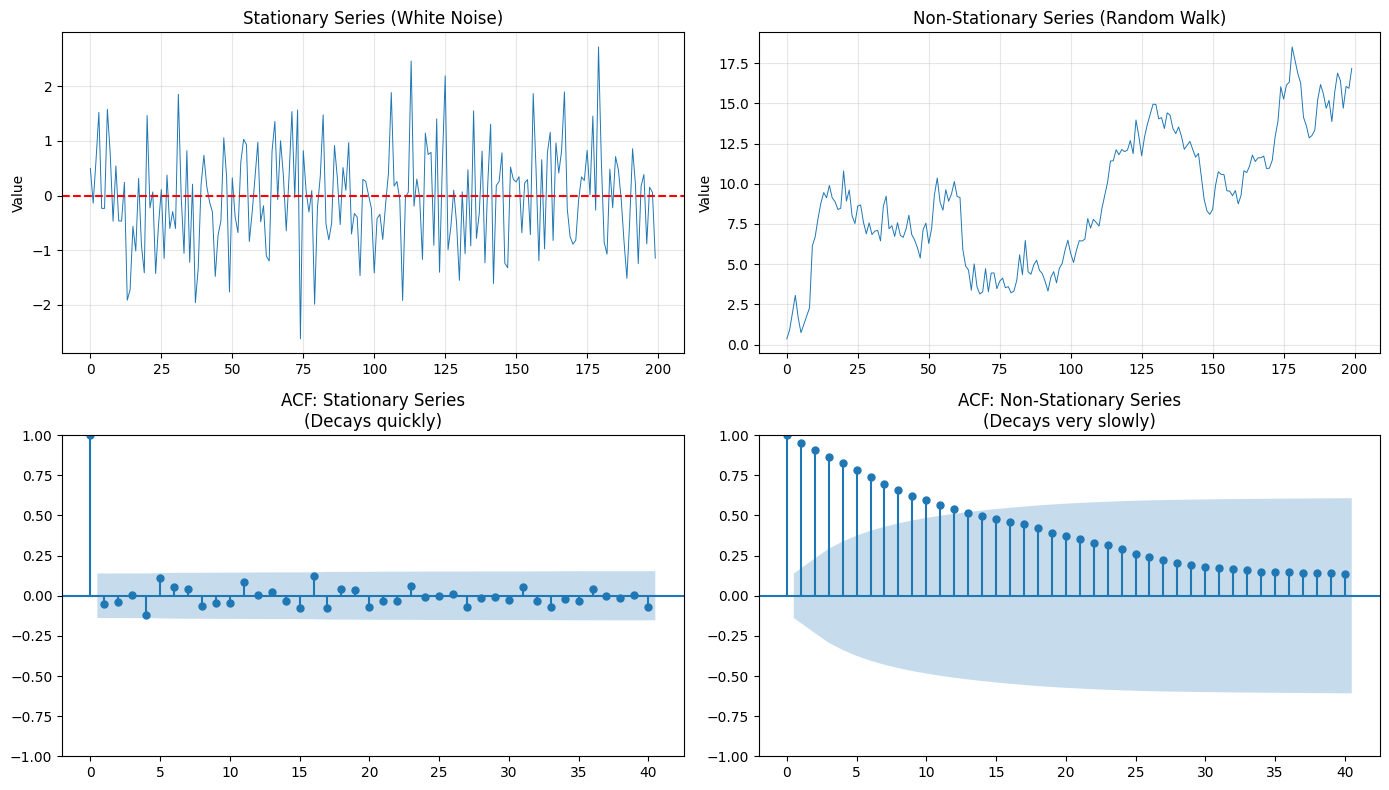

In [ ]:
print("=" * 60)
print("Section 1: Stationary vs Non-Stationary Series")
print("=" * 60)

n = 200

# Stationary: white noise around constant mean
stationary_series = np.random.normal(0, 1, n)

# Non-stationary: random walk (cumulative sum of noise)
non_stationary_series = np.cumsum(np.random.normal(0, 1, n))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(stationary_series, linewidth=0.7)
axes[0, 0].axhline(y=0, color='r', linestyle='--')
axes[0, 0].set_title('Stationary Series (White Noise)')
axes[0, 0].set_ylabel('Value')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(non_stationary_series, linewidth=0.7)
axes[0, 1].set_title('Non-Stationary Series (Random Walk)')
axes[0, 1].set_ylabel('Value')
axes[0, 1].grid(True, alpha=0.3)

# ACF for stationary vs non-stationary
plot_acf(stationary_series, lags=40, ax=axes[1, 0])
axes[1, 0].set_title('ACF: Stationary Series\n(Decays quickly)')

plot_acf(non_stationary_series, lags=40, ax=axes[1, 1])
axes[1, 1].set_title('ACF: Non-Stationary Series\n(Decays very slowly)')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_stationarity.png'), dpi=100)


## Section 2: ADF Test (Augmented Dickey-Fuller)


In [ ]:
print("\n" + "=" * 60)
print("Section 2: ADF Test")
print("=" * 60)


def check_stationarity(series, name="Series"):
    """Perform ADF test and interpret results."""
    result = adfuller(series.dropna() if hasattr(series, 'dropna') else series)

    print(f"\n  {name}:")
    print(f"    ADF Statistic: {result[0]:.4f}")
    print(f"    p-value:       {result[1]:.6f}")
    print(f"    Critical Values:")
    for key, value in result[4].items():
        print(f"      {key}: {value:.4f}")

    if result[1] < 0.05:
        print(f"    Conclusion: Stationary (reject H0, p < 0.05)")
    else:
        print(f"    Conclusion: Non-stationary (fail to reject H0, p >= 0.05)")
    return result[1] < 0.05


check_stationarity(stationary_series, "Stationary Series")
check_stationarity(non_stationary_series, "Non-Stationary Series")



Section 2: ADF Test

  Stationary Series:
    ADF Statistic: -14.7442
    p-value:       0.000000
    Critical Values:
      1%: -3.4636
      5%: -2.8762
      10%: -2.5746
    Conclusion: Stationary (reject H0, p < 0.05)

  Non-Stationary Series:
    ADF Statistic: -1.8198
    p-value:       0.370672
    Critical Values:
      1%: -3.4636
      5%: -2.8762
      10%: -2.5746
    Conclusion: Non-stationary (fail to reject H0, p >= 0.05)


np.False_

## Section 3: KPSS Test (Complement to ADF)


In [ ]:
print("\n" + "=" * 60)
print("Section 3: KPSS Test (Complements ADF)")
print("=" * 60)

for name, data in [("Stationary", stationary_series), ("Non-Stationary", non_stationary_series)]:
    try:
        kpss_stat, kpss_pval, _, kpss_cv = kpss(data, regression='c', nlags='auto')
        print(f"\n  {name}:")
        print(f"    KPSS Statistic: {kpss_stat:.4f}")
        print(f"    p-value:        {kpss_pval:.4f}")
        if kpss_pval < 0.05:
            print(f"    Conclusion: Non-stationary (reject H0 of stationarity)")
        else:
            print(f"    Conclusion: Stationary (fail to reject H0)")
    except Exception as e:
        print(f"  {name}: KPSS test failed - {e}")



Section 3: KPSS Test (Complements ADF)

  Stationary:
    KPSS Statistic: 0.1797
    p-value:        0.1000
    Conclusion: Stationary (fail to reject H0)

  Non-Stationary:
    KPSS Statistic: 1.3158
    p-value:        0.0100
    Conclusion: Non-stationary (reject H0 of stationarity)


## Section 4: Making Data Stationary


In [ ]:
print("\n" + "=" * 60)
print("Section 4: Transformations to Achieve Stationarity")
print("=" * 60)

# 4a: Differencing
diff_1 = pd.Series(non_stationary_series).diff(1).dropna()
diff_2 = pd.Series(non_stationary_series).diff(2).dropna()

print("\n  4a: Differencing:")
check_stationarity(diff_1, "First Difference")
check_stationarity(diff_2, "Second Difference")

# 4b: Log Transform
# Make data positive for log transform
positive_ts = non_stationary_series - non_stationary_series.min() + 1
log_ts = np.log(positive_ts)

print("\n  4b: Log Transform:")
check_stationarity(log_ts, "Log Transformed")

# 4c: Log + Difference
log_diff = pd.Series(log_ts).diff(1).dropna()
print("\n  4c: Log + Difference:")
check_stationarity(log_diff, "Log + First Difference")

# 4d: Detrending
X = np.arange(len(non_stationary_series)).reshape(-1, 1)
model = LinearRegression().fit(X, non_stationary_series)
trend_line = model.predict(X)
detrended = non_stationary_series - trend_line

print("\n  4d: Detrending (Linear Regression):")
check_stationarity(detrended, "Detrended Series")

# 4e: SciPy detrend
detrended_scipy = signal.detrend(non_stationary_series)
print("\n  4e: SciPy signal.detrend:")
check_stationarity(detrended_scipy, "SciPy Detrended")



Section 4: Transformations to Achieve Stationarity

  4a: Differencing:

  First Difference:
    ADF Statistic: -14.6980
    p-value:       0.000000
    Critical Values:
      1%: -3.4638
      5%: -2.8763
      10%: -2.5746
    Conclusion: Stationary (reject H0, p < 0.05)

  Second Difference:
    ADF Statistic: -3.8921
    p-value:       0.002094
    Critical Values:
      1%: -3.4662
      5%: -2.8773
      10%: -2.5752
    Conclusion: Stationary (reject H0, p < 0.05)

  4b: Log Transform:

  Log Transformed:
    ADF Statistic: -3.4067
    p-value:       0.010734
    Critical Values:
      1%: -3.4638
      5%: -2.8763
      10%: -2.5746
    Conclusion: Stationary (reject H0, p < 0.05)

  4c: Log + Difference:

  Log + First Difference:
    ADF Statistic: -13.8947
    p-value:       0.000000
    Critical Values:
      1%: -3.4638
      5%: -2.8763
      10%: -2.5746
    Conclusion: Stationary (reject H0, p < 0.05)

  4d: Detrending (Linear Regression):

  Detrended Series:
    ADF 

np.False_

## Section 5: Seasonal Differencing


In [ ]:
print("\n" + "=" * 60)
print("Section 5: Seasonal Differencing")
print("=" * 60)

# Create data with seasonality
t = np.arange(200)
seasonal_data = 5 * np.sin(2 * np.pi * t / 12) + 0.1 * t + np.random.normal(0, 0.5, 200)
seasonal_series = pd.Series(seasonal_data)

# Seasonal differencing (period=12)
seasonal_diff = seasonal_series.diff(12).dropna()

print("\n  Original seasonal series:")
check_stationarity(seasonal_series, "Original (with seasonality)")

print("\n  After seasonal differencing (period=12):")
check_stationarity(seasonal_diff, "Seasonal Diff (12)")

print("\nDone! Stationarity analysis complete.")



Section 5: Seasonal Differencing

  Original seasonal series:

  Original (with seasonality):
    ADF Statistic: -0.3216
    p-value:       0.922385
    Critical Values:
      1%: -3.4658
      5%: -2.8771
      10%: -2.5751
    Conclusion: Non-stationary (fail to reject H0, p >= 0.05)

  After seasonal differencing (period=12):

  Seasonal Diff (12):
    ADF Statistic: -5.3752
    p-value:       0.000004
    Critical Values:
      1%: -3.4683
      5%: -2.8782
      10%: -2.5757
    Conclusion: Stationary (reject H0, p < 0.05)

Done! Stationarity analysis complete.


---
## Trend


In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.linear_model import LinearRegression
from scipy import stats
import os, warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)
n = 365
t = np.arange(n)


## Section 1: Types of Trends


Section 1: Types of Trends


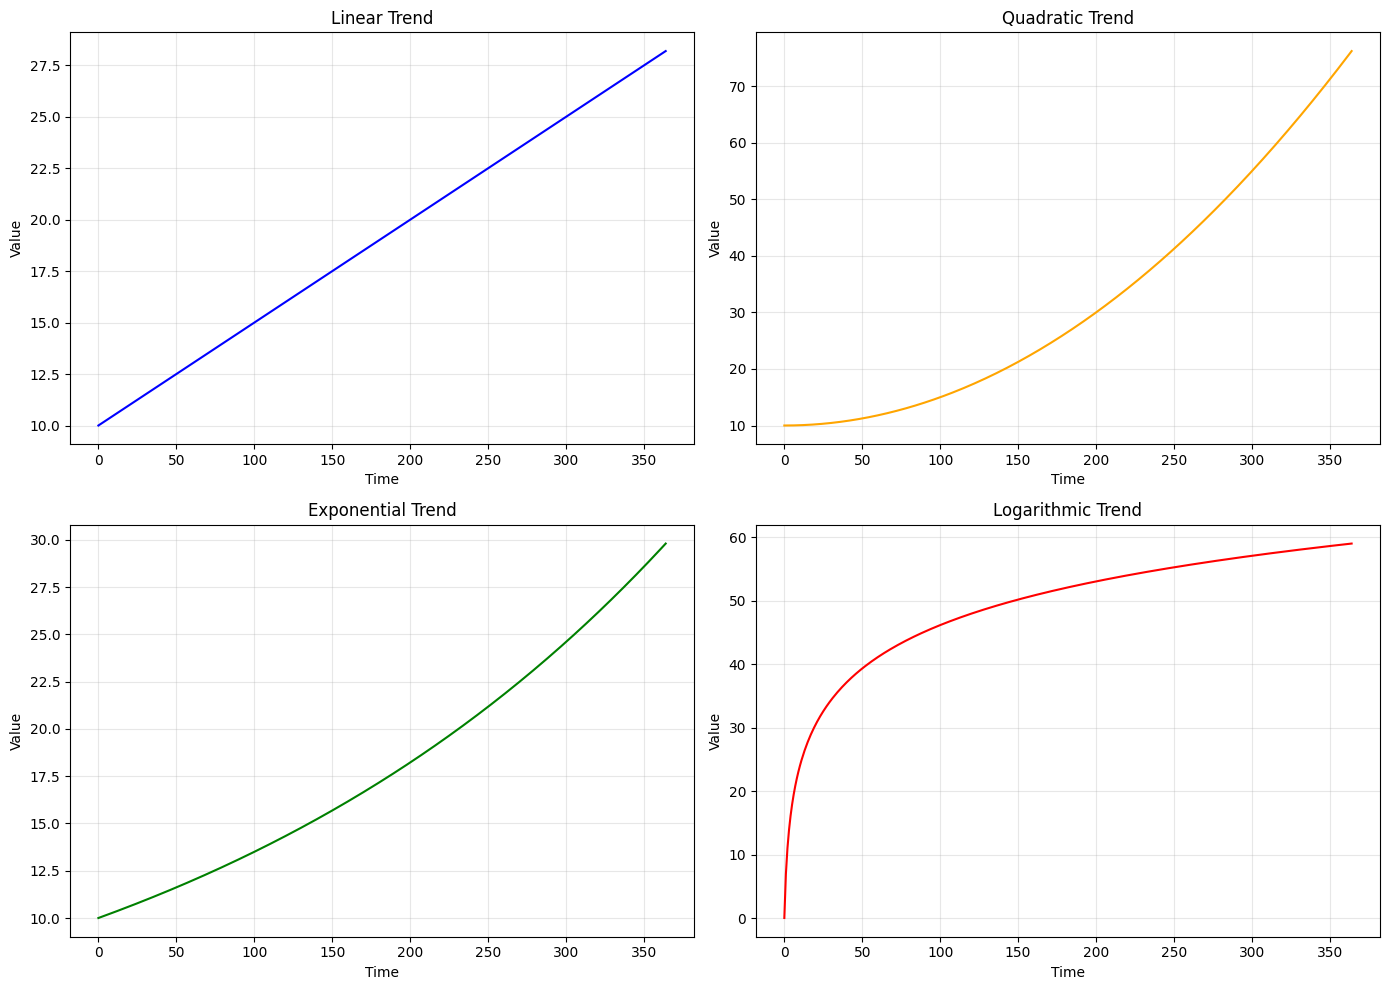

In [ ]:
print("=" * 60)
print("Section 1: Types of Trends")
print("=" * 60)

linear_trend = 0.05 * t + 10
quadratic_trend = 0.0005 * t**2 + 10
exponential_trend = 10 * np.exp(0.003 * t)
logarithmic_trend = 10 * np.log(t + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
trends = [
    (axes[0, 0], t, linear_trend, 'Linear Trend', 'blue'),
    (axes[0, 1], t, quadratic_trend, 'Quadratic Trend', 'orange'),
    (axes[1, 0], t, exponential_trend, 'Exponential Trend', 'green'),
    (axes[1, 1], t, logarithmic_trend, 'Logarithmic Trend', 'red'),
]
for ax, x, y, title, color in trends:
    ax.plot(x, y, color=color, linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel('Time')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_trend_types.png'), dpi=100)


## Section 2: Random Walk with Drift (Stochastic Trend)



Section 2: Random Walk with Drift


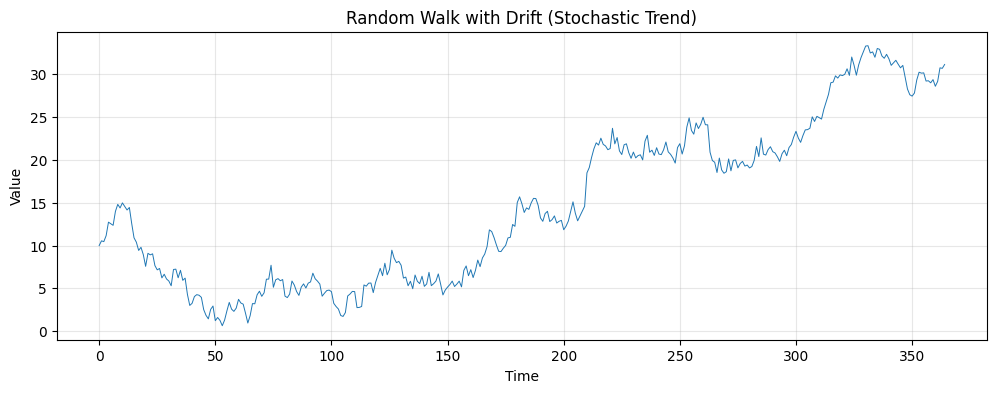

In [ ]:
print("\n" + "=" * 60)
print("Section 2: Random Walk with Drift")
print("=" * 60)

random_walk = [10.0]
for _ in range(1, n):
    next_step = random_walk[-1] + 0.05 + np.random.normal(0, 1)
    random_walk.append(next_step)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(random_walk, linewidth=0.7)
ax.set_title('Random Walk with Drift (Stochastic Trend)')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '04_random_walk.png'), dpi=100)


## Section 3: Moving Average for Trend Extraction



Section 3: Trend Extraction with Moving Average


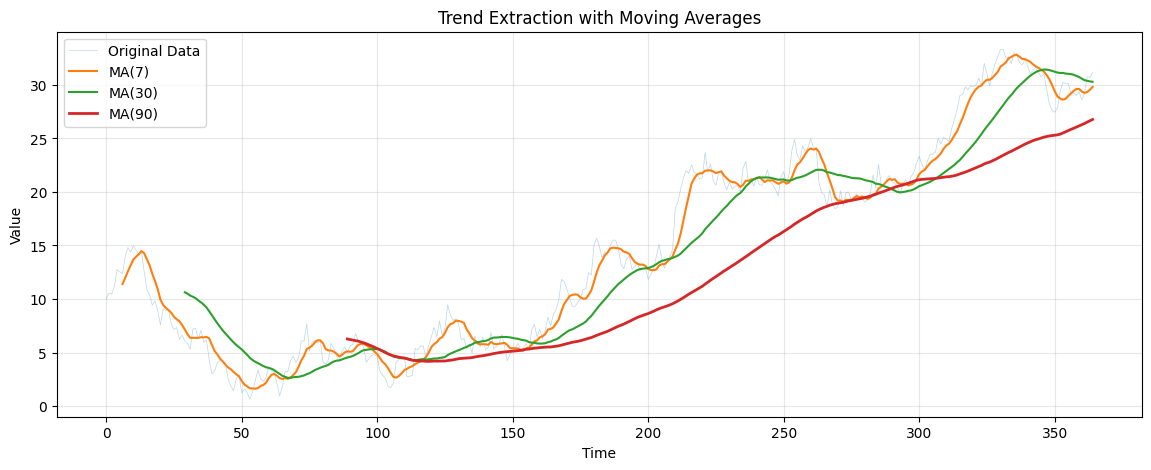

In [ ]:
print("\n" + "=" * 60)
print("Section 3: Trend Extraction with Moving Average")
print("=" * 60)

data = pd.Series(random_walk)
ma_7 = data.rolling(window=7).mean()
ma_30 = data.rolling(window=30).mean()
ma_90 = data.rolling(window=90).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(data, alpha=0.3, linewidth=0.5, label='Original Data')
ax.plot(ma_7, linewidth=1.5, label='MA(7)')
ax.plot(ma_30, linewidth=1.5, label='MA(30)')
ax.plot(ma_90, linewidth=2, label='MA(90)')
ax.set_title('Trend Extraction with Moving Averages')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '04_moving_average.png'), dpi=100)


## Section 4: Statistical Trend Test (Mann-Kendall)


In [ ]:
print("\n" + "=" * 60)
print("Section 4: Mann-Kendall Trend Test")
print("=" * 60)

# Mann-Kendall implementation
def mann_kendall_test(data):
    """Simple Mann-Kendall trend test."""
    n = len(data)
    s = 0
    for i in range(n - 1):
        for j in range(i + 1, n):
            s += np.sign(data[j] - data[i])
    # Variance of S
    var_s = (n * (n - 1) * (2 * n + 5)) / 18
    # Standardized test statistic
    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0
    # Two-tailed p-value
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return s, z, p_value


s_stat, z_stat, p_val = mann_kendall_test(data.values)
print(f"  S-statistic: {s_stat}")
print(f"  Z-statistic: {z_stat:.4f}")
print(f"  p-value: {p_val:.6f}")
print(f"  Conclusion: {'Significant trend' if p_val < 0.05 else 'No significant trend'}")



Section 4: Mann-Kendall Trend Test
  S-statistic: 44378.0
  Z-statistic: 19.0526
  p-value: 0.000000
  Conclusion: Significant trend


## Section 5: Linear Regression Trend



Section 5: Trend Slope via Linear Regression
  Trend slope: 0.0793 per time step
  Intercept: 0.2199
  R-squared: 0.7844


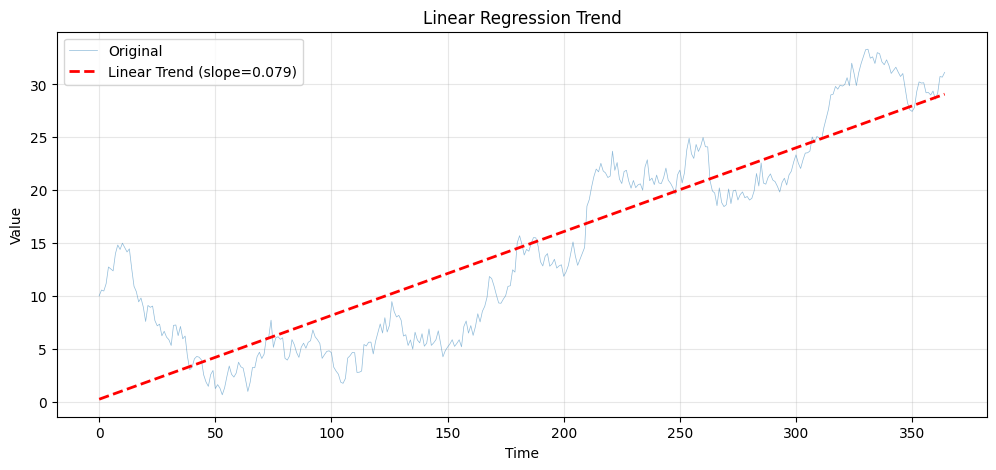

In [ ]:
print("\n" + "=" * 60)
print("Section 5: Trend Slope via Linear Regression")
print("=" * 60)

X = np.arange(len(data)).reshape(-1, 1)
model = LinearRegression().fit(X, data)
trend_line = model.predict(X)
slope = model.coef_[0]

print(f"  Trend slope: {slope:.4f} per time step")
print(f"  Intercept: {model.intercept_:.4f}")
print(f"  R-squared: {model.score(X, data):.4f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(data.values, alpha=0.5, linewidth=0.5, label='Original')
ax.plot(trend_line, 'r--', linewidth=2, label=f'Linear Trend (slope={slope:.3f})')
ax.set_title('Linear Regression Trend')
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, '04_linear_trend.png'), dpi=100)


## Section 6: Trend Removal Methods


In [ ]:
print("\n" + "=" * 60)
print("Section 6: Trend Removal Methods")
print("=" * 60)

data_series = pd.Series(random_walk)

# Method 1: Differencing
detrended_diff = data_series.diff(1).dropna()
diff_adf = adfuller(detrended_diff)

# Method 2: Subtract fitted line
detrended_subtract = data_series.values - trend_line
det_sub_adf = adfuller(detrended_subtract)

# Method 3: Log returns
positive_data = data_series - data_series.min() + 1
log_returns = np.log(positive_data).diff(1).dropna()
log_ret_adf = adfuller(log_returns)

print(f"  Method 1: First Difference - ADF p-value: {diff_adf[1]:.6f}")
print(f"  Method 2: Subtract Trend - ADF p-value: {det_sub_adf[1]:.6f}")
print(f"  Method 3: Log Returns    - ADF p-value: {log_ret_adf[1]:.6f}")



Section 6: Trend Removal Methods
  Method 1: First Difference - ADF p-value: 0.000000
  Method 2: Subtract Trend - ADF p-value: 0.081578
  Method 3: Log Returns    - ADF p-value: 0.000002


## Section 7: Seasonal Decomposition



Section 7: Seasonal Decomposition

  Variance Contribution:
    Trend:     83.9%
    Seasonal:  0.5%
    Residual:  7.4%


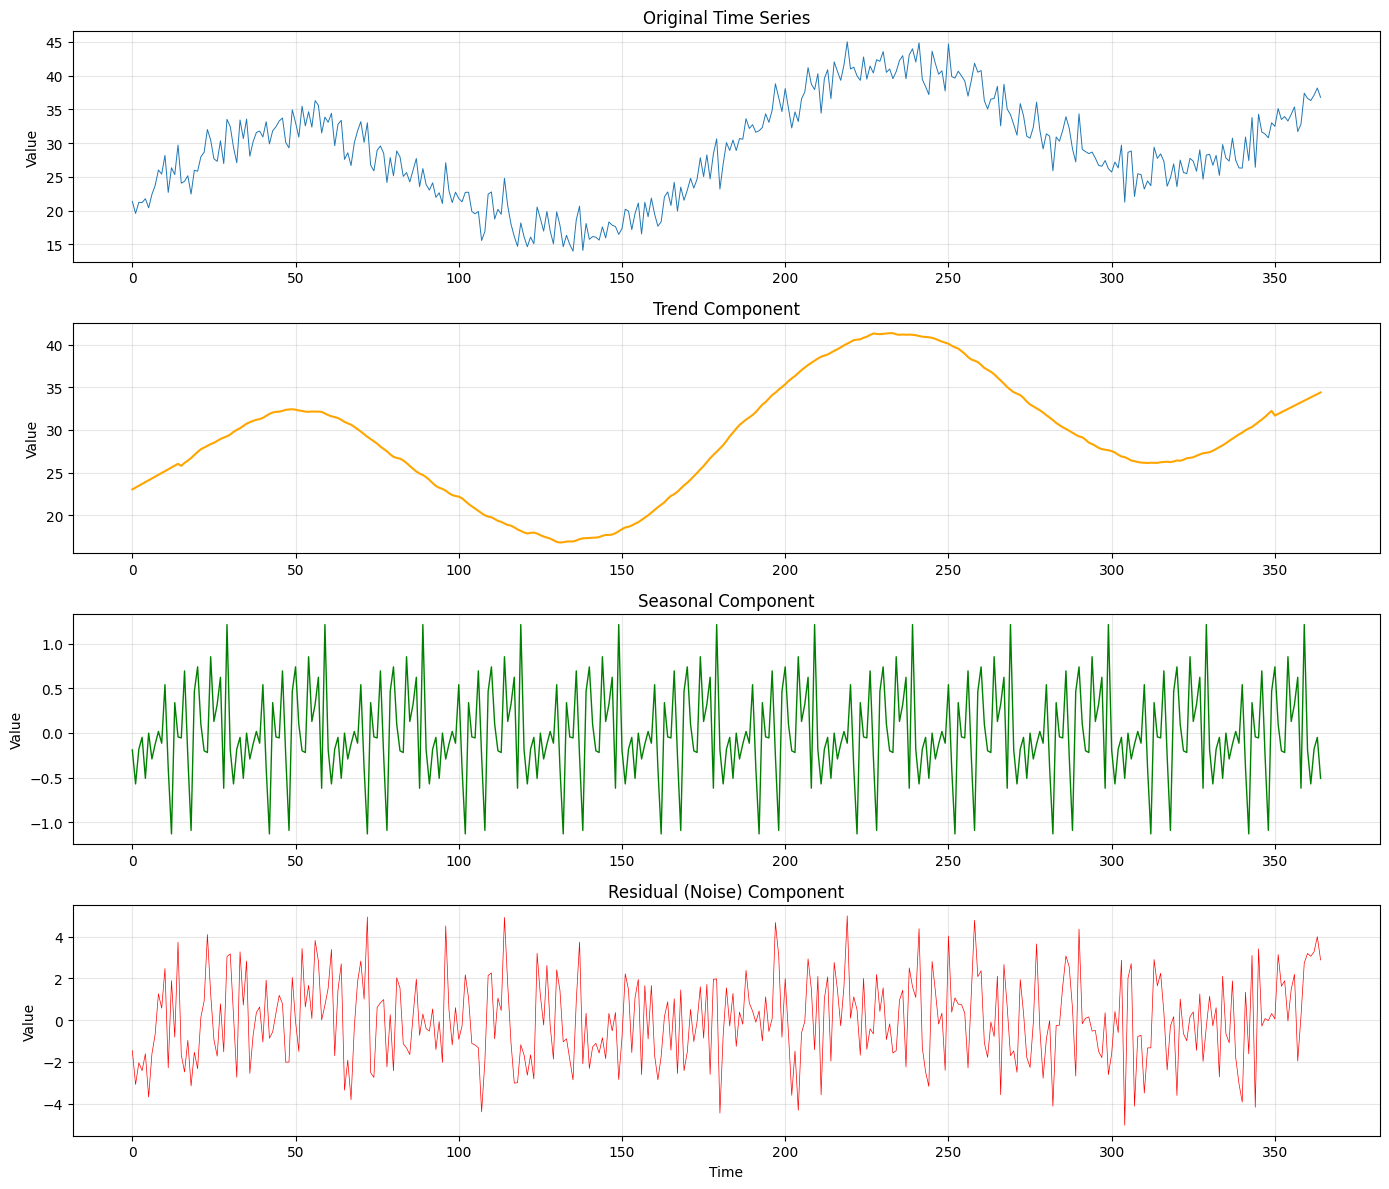

In [ ]:
print("\n" + "=" * 60)
print("Section 7: Seasonal Decomposition")
print("=" * 60)

# Create data with trend + seasonality + noise
t = np.arange(365)
trend = 0.05 * t + 20
seasonal = 10 * np.sin(2 * np.pi * t / 365 * 2)  # two cycles per year
noise = np.random.normal(0, 2, 365)
ts_data = trend + seasonal + noise

decomposition_add = seasonal_decompose(ts_data, model='additive', period=30, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(14, 12))
axes[0].plot(ts_data, linewidth=0.7)
axes[0].set_title('Original Time Series')
axes[0].set_ylabel('Value')
axes[0].grid(True, alpha=0.3)

axes[1].plot(decomposition_add.trend, color='orange', linewidth=1.5)
axes[1].set_title('Trend Component')
axes[1].set_ylabel('Value')
axes[1].grid(True, alpha=0.3)

axes[2].plot(decomposition_add.seasonal, color='green', linewidth=1)
axes[2].set_title('Seasonal Component')
axes[2].set_ylabel('Value')
axes[2].grid(True, alpha=0.3)

axes[3].plot(decomposition_add.resid, color='red', linewidth=0.5)
axes[3].set_title('Residual (Noise) Component')
axes[3].set_xlabel('Time')
axes[3].set_ylabel('Value')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_decomposition.png'), dpi=100)
# Variance contribution
total_var = np.var(ts_data)
trend_var = np.nanvar(decomposition_add.trend)
seasonal_var = np.nanvar(decomposition_add.seasonal)
resid_var = np.nanvar(decomposition_add.resid)

print(f"\n  Variance Contribution:")
print(f"    Trend:     {trend_var/total_var*100:.1f}%")
print(f"    Seasonal:  {seasonal_var/total_var*100:.1f}%")
print(f"    Residual:  {resid_var/total_var*100:.1f}%")


## Section 8: Multiplicative Decomposition


In [ ]:
print("\n" + "=" * 60)
print("Section 8: Multiplicative Decomposition")
print("=" * 60)

# Multiplicative example
multiplicative_data = trend * (1 + 0.3 * np.sin(2 * np.pi * t / 365)) * np.exp(np.random.normal(0, 0.05, 365))
decomposition_mult = seasonal_decompose(multiplicative_data, model='multiplicative',
                                         period=30, extrapolate_trend='freq')

print("  Multiplicative model: Y = Trend * Seasonal * Residual")
print(f"  Original range: [{multiplicative_data.min():.1f}, {multiplicative_data.max():.1f}]")

# Convert multiplicative to additive with log
log_data = np.log(np.maximum(multiplicative_data, 1e-10))
decomposition_log = seasonal_decompose(log_data, model='additive', period=30, extrapolate_trend='freq')
print("  Log transform converts multiplicative -> additive")

print("\nDone! Trend, Seasonality, and Noise analysis complete.")



Section 8: Multiplicative Decomposition
  Multiplicative model: Y = Trend * Seasonal * Residual
  Original range: [18.9, 39.5]
  Log transform converts multiplicative -> additive

Done! Trend, Seasonality, and Noise analysis complete.
